In [17]:
import pandas as pd
import missingno as msno
import numpy as np
from scipy import stats

In [2]:

df = pd.read_parquet("../data/processed/games.parquet")


In [3]:
print(df.head(5))

  player_id   game_id       start_ms         end_ms  color  own_rating  \
0  aaradhya  QiWrCsPU  1706700225612  1706700512944  black        1904   
1  aaradhya  CAOKOa2f  1706700550461  1706700765384  white        1909   
2  aaradhya  2G7e3KbB  1706700819728  1706701013476  white        1920   
3  aaradhya  XAT3TuHi  1706701038414  1706701125229  black        1926   
4  aaradhya  BWk4ED48  1706701226677  1706701409694  white        1928   

   opp_rating  rating_diff  score  expected  ...  session_id game_no  \
0        1774         -130    1.0  0.678817  ...           1       0   
1        1997           88    1.0  0.375998  ...           1       1   
2        1811         -109    1.0  0.651912  ...           1       2   
3        1606         -320    1.0  0.863193  ...           1       3   
4        1847          -81    0.0  0.614501  ...           1       4   

   game_no_cap   gap_min  prev_score  lost_prev  drew_prev  streak_in  \
0            0       NaN         NaN          0  

<Axes: >

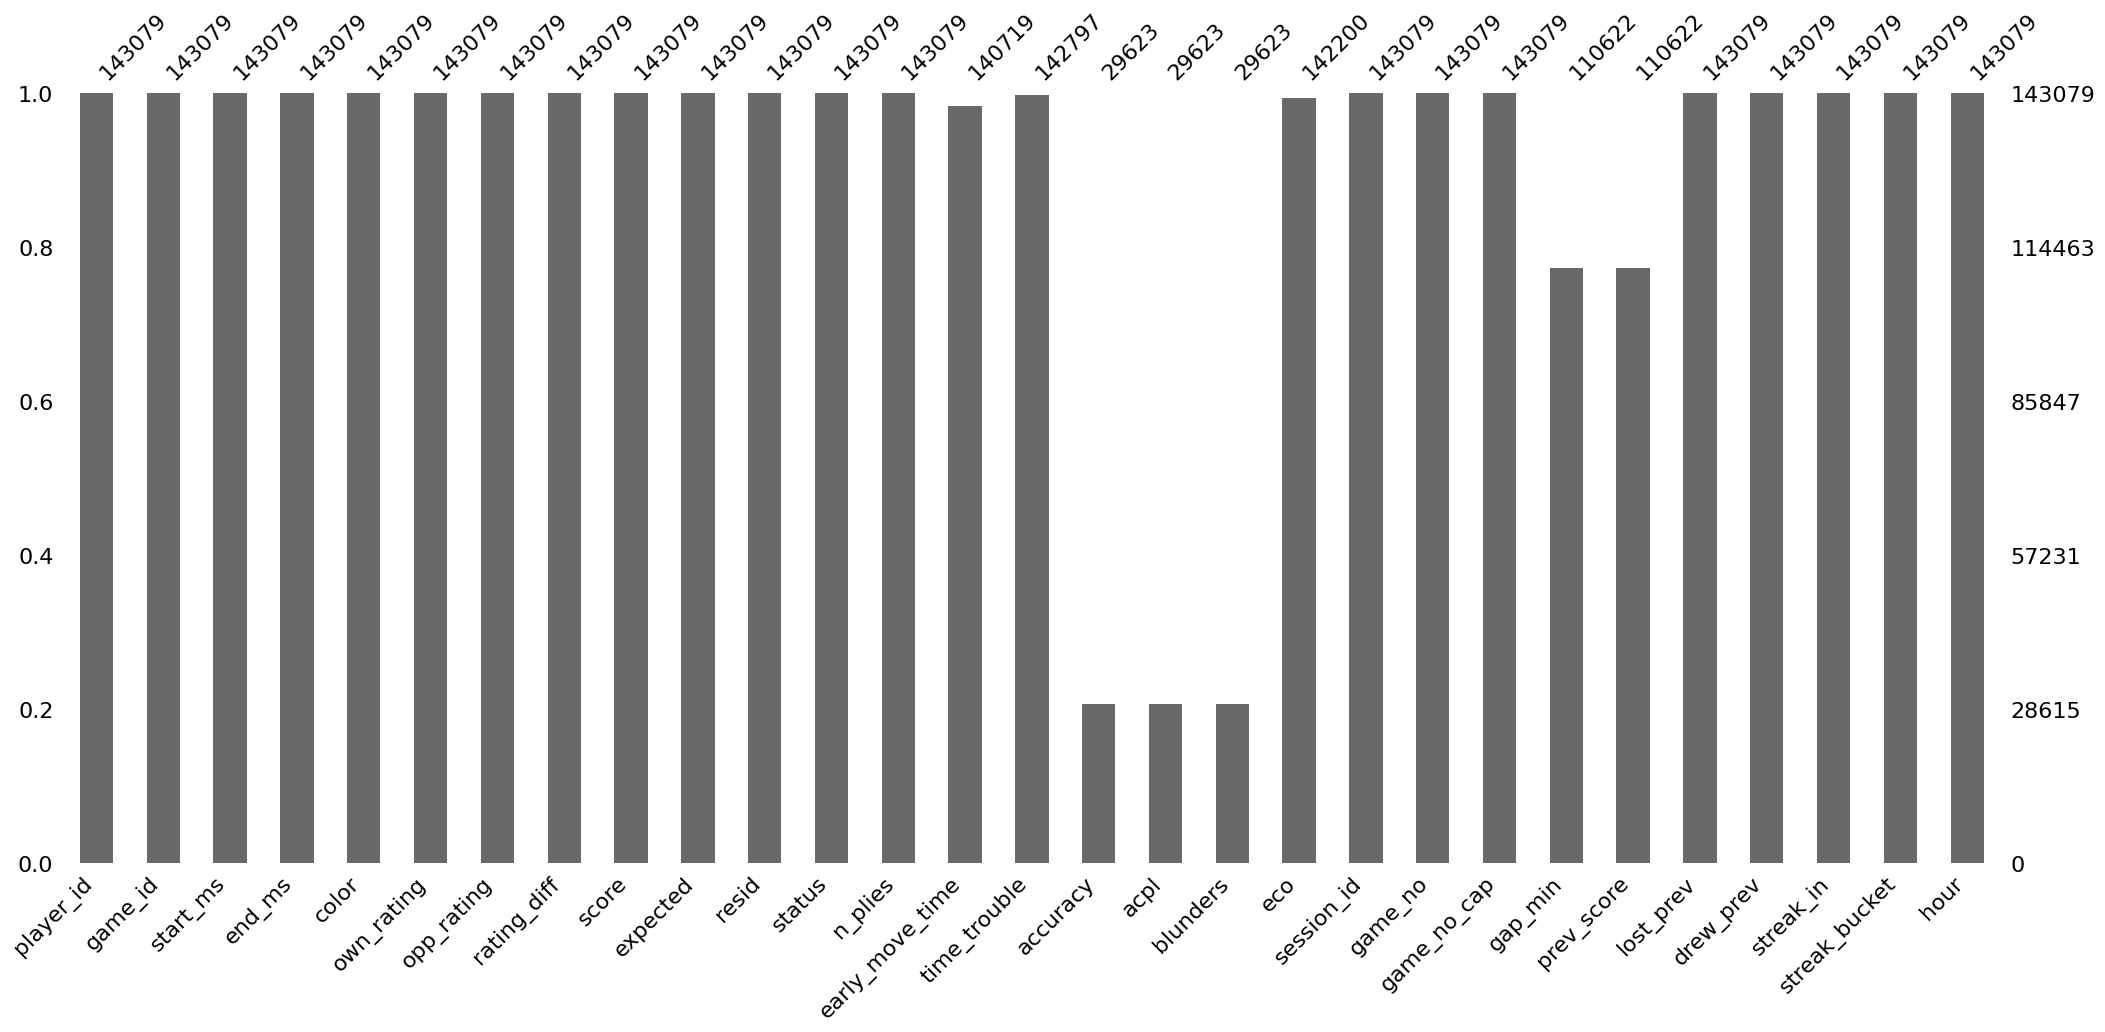

In [4]:
msno.bar(df)

<Axes: >

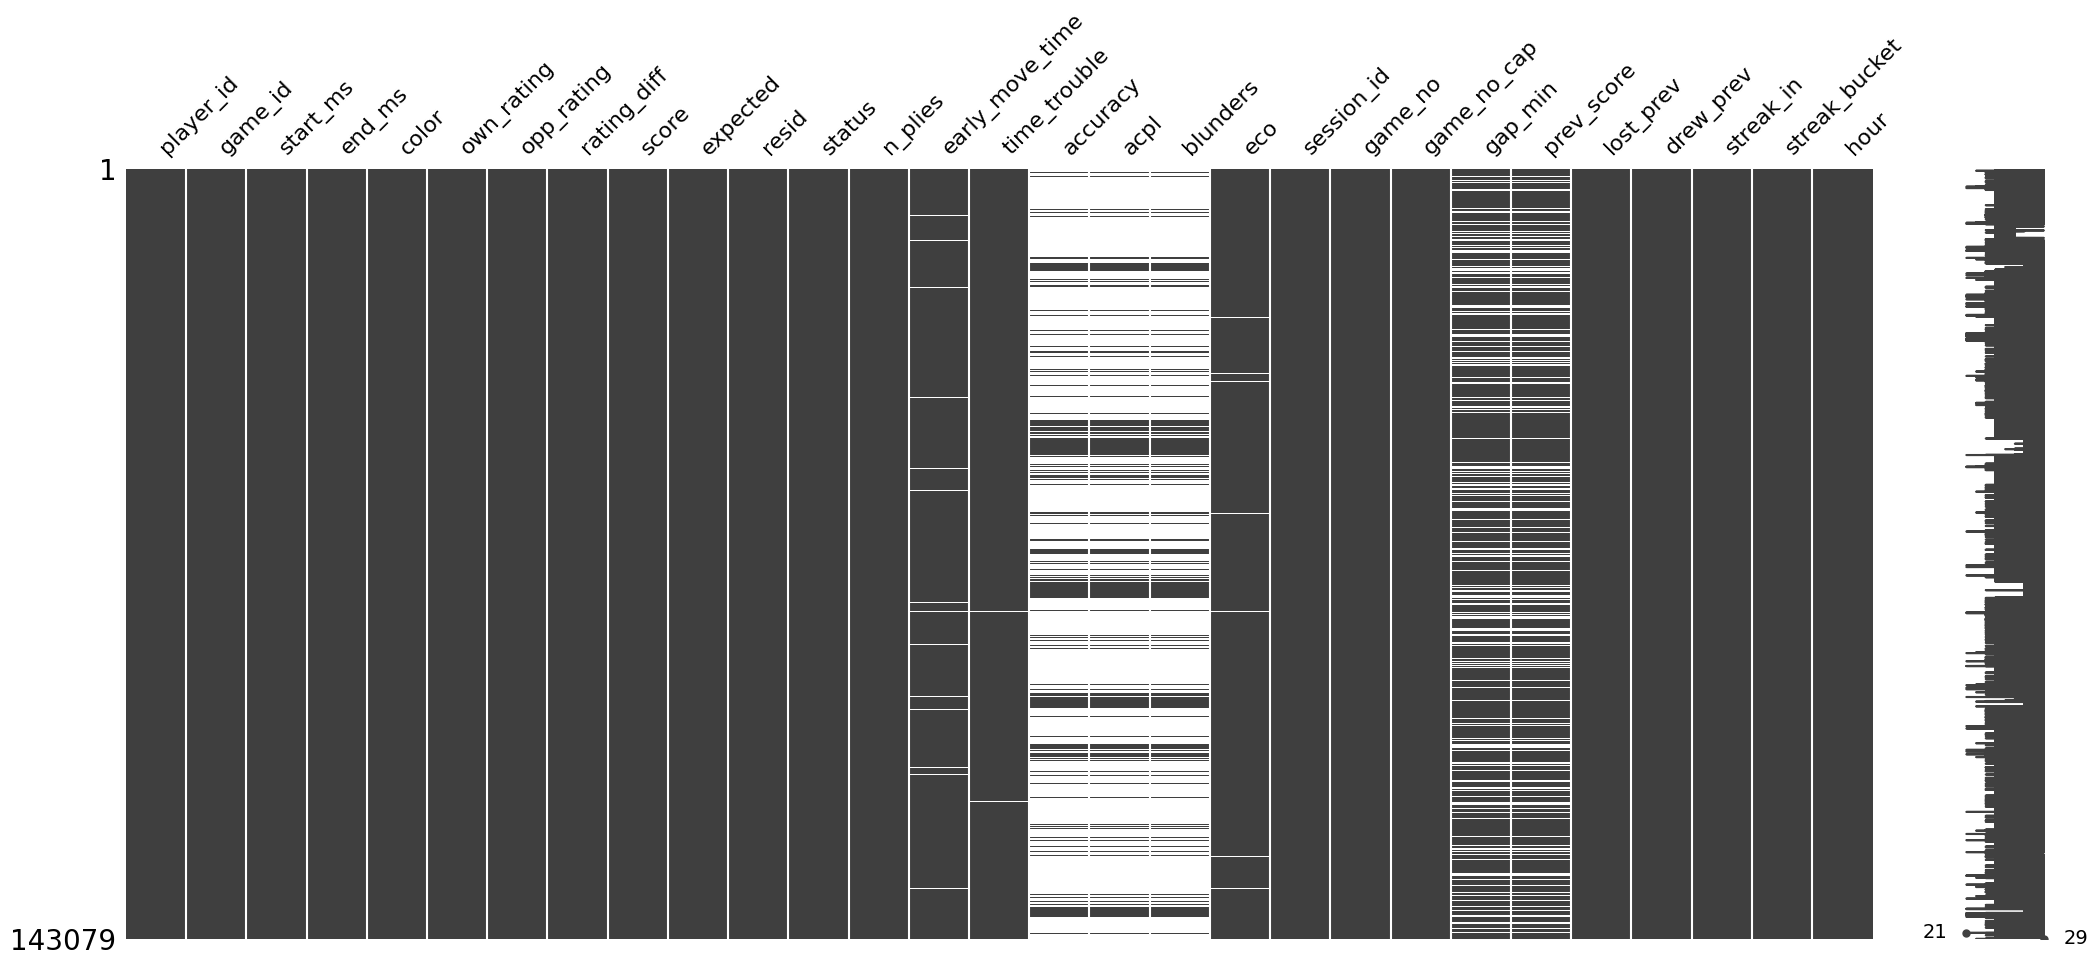

In [5]:
msno.matrix(df, filter = "NaN")

In [6]:
df_filtered = df.dropna(subset = ["lost_prev"])

df_filtered.head(5)

,player_id,game_id,start_ms,end_ms,color,own_rating,opp_rating,rating_diff,score,expected,...,session_id,game_no,game_no_cap,gap_min,prev_score,lost_prev,drew_prev,streak_in,streak_bucket,hour
0,aaradhya,QiWrCsPU,1706700225612,1706700512944,black,1904,1774,-130,1.0,0.678817,...,1,0,0,NaN,NaN,0,0,0.0,0,11
1,aaradhya,CAOKOa2f,1706700550461,1706700765384,white,1909,1997,88,1.0,0.375998,...,1,1,1,0.625283,1.0,0,0,0.0,0,11
2,aaradhya,2G7e3KbB,1706700819728,1706701013476,white,1920,1811,-109,1.0,0.651912,...,1,2,2,0.905733,1.0,0,0,0.0,0,11
3,aaradhya,XAT3TuHi,1706701038414,1706701125229,black,1926,1606,-320,1.0,0.863193,...,1,3,3,0.415633,1.0,0,0,0.0,0,11
4,aaradhya,BWk4ED48,1706701226677,1706701409694,white,1928,1847,-81,0.0,0.614501,...,1,4,4,1.690800,1.0,0,0,0.0,0,11


In [7]:
len(df_filtered)

143079

In [8]:
after_lost = df_filtered[df_filtered["lost_prev"] == 1]
len(after_lost)

46687

In [9]:
after_lost = after_lost[["player_id", "score", "lost_prev"]]


In [10]:
wins_after_loss = after_lost[after_lost["score"] == 1.0]
win_rate = len(wins_after_loss) / len(after_lost)
print(f"Win rate after a loss: {win_rate:.2%}")

Win rate after a loss: 47.37%


In [13]:
after_lost_no_draws = after_lost[after_lost["score"] != 0.5]
summary = after_lost_no_draws["score"].describe()

print(summary)

count    44537.000000
mean         0.496531
std          0.499994
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          1.000000
Name: score, dtype: float64


In [18]:

def gap(g):
    a = g[g.prev_score == 0].resid
    b = g[g.prev_score == 1].resid
    return a.mean() - b.mean() if len(a) > 10 and len(b) > 10 else np.nan

pg = df_filtered.groupby('player_id').apply(gap, include_groups=False).dropna()
print(stats.ttest_1samp(pg, 0))          # parametric
print(stats.wilcoxon(pg))                # non-parametric
print(stats.binomtest(int((pg < 0).sum()), len(pg), 0.5))   # sign test

TtestResult(statistic=np.float64(-3.2096759721387547), pvalue=np.float64(0.001772266557509851), df=np.int64(103))
WilcoxonResult(statistic=np.float64(1678.0), pvalue=np.float64(0.0006462228346002815))
BinomTestResult(k=69, n=104, alternative='two-sided', statistic=0.6634615384615384, pvalue=0.0011086208878113386)
